# TASK 07 — Latent Factor Model (TruncatedSVD)

Bu defter, MovieLens 32M puanlarından seyrek kullanıcı-film matrisi kurar ve `sklearn.decomposition.TruncatedSVD` ile düşük-rank latent faktörler öğrenir. Matris gözlenen puan değerlerini taşır; gözlenmeyen etkileşimler sıfır olarak kalır. Sıralama skoru kullanıcı faktörü ile film faktörünün iç çarpımıdır.

Model seçimi yalnızca eğitim içi 2019 validation bölmesinde, iki sınırlı faktör sayısı (20 ve 40) karşılaştırılarak yapılır. Seçilen boyutla final model yalnızca 2020 öncesi eğitim puanlarında yeniden kurulur. Test hedefleri yalnızca final değerlendirmede kullanılır. Aday skorları küçük kullanıcı dilimleri halinde hesaplanır; hiçbir aşamada 7.817 × 84.432 veya daha büyük yoğun skor matrisi oluşturulmaz.


## 1. Ortam ve ortak protokol

Config dosyasındaki kesme, kullanıcı sayısı, aday sayısı ve seed değerlerini kullan. Validation için sabit, eğitim içi kesme 2019-01-01 UTC’dir. Test döneminin hiçbir verisi faktör sayısını seçmek için kullanılmaz.


In [1]:
import os
import csv
import time
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from threadpoolctl import threadpool_limits
from IPython.display import display

cwd = os.getcwd()
project_root = os.path.abspath(os.path.join(cwd, '..')) if os.path.basename(cwd) == 'notebooks' else os.path.abspath(cwd)
with open(os.path.join(project_root, 'config.yaml'), encoding='utf-8') as f:
    config = yaml.safe_load(f)
dataset_dir = config['dataset']['directory']
ratings_path = os.path.join(dataset_dir, config['dataset']['ratings'])
results_path = os.path.join(project_root, 'results')
figures_path = os.path.join(results_path, 'figures')
os.makedirs(figures_path, exist_ok=True)
cutoff = int(config['evaluation']['temporal_split']['cutoff_timestamp'])
validation_cutoff = int(pd.Timestamp('2019-01-01 00:00:00', tz='UTC').timestamp())
seed = int(config['project']['random_seed'])
expected_users = int(config['evaluation']['evaluable_users']['count'])
expected_items = int(config['evaluation']['candidate_universe']['total_items'])
print(f'Project: {project_root}; dataset: {dataset_dir}')
print(f'Final cutoff: {config["evaluation"]["temporal_split"]["cutoff_utc"]}; validation cutoff: 2019-01-01 UTC')
print(f'Random seed: {seed}; candidate ranks: [20, 40]')
assert os.path.isfile(ratings_path), f'Missing ratings file: {ratings_path}'


Project: C:\OneriAlgoritmalariProjesi; dataset: C:/ml-32m
Final cutoff: 2020-01-01 00:00:00 UTC; validation cutoff: 2019-01-01 UTC
Random seed: 42; candidate ranks: [20, 40]


## 2. Ortak test hedefleri ve aday evreni

Aynı benchmark protokolü kullanılır: 2020 öncesi eğitim, 2020+ test; en az bir eğitim ve test etkileşimi bulunan 7.817 kullanıcı; tam MovieLens rated-movies evrenindeki 84.432 film. Her kullanıcının eğitimde gördüğü filmler öneri listesinden çıkarılır. Testte puanlanan bütün filmler relevance hedefidir; test puanlarına eşik uygulanmaz, böylece TASK 05 ve TASK 06 ile aynı tanım korunur.


In [2]:
t0 = time.time()
dtypes = {'userId':'int32','movieId':'int32','rating':'float32','timestamp':'int32'}
all_ratings = pd.read_csv(ratings_path, usecols=['userId','movieId','rating','timestamp'], dtype=dtypes)
cut_train_mask = all_ratings['timestamp'] < cutoff
train_user_ids = np.sort(all_ratings.loc[cut_train_mask, 'userId'].unique())
test_user_ids = np.sort(all_ratings.loc[~cut_train_mask, 'userId'].unique())
evaluable_users = np.intersect1d(train_user_ids, test_user_ids).astype(np.int32)
candidate_items = np.sort(all_ratings['movieId'].unique()).astype(np.int32)
test_eval = all_ratings.loc[(~cut_train_mask) & all_ratings['userId'].isin(evaluable_users), ['userId','movieId']].copy()
test_targets = test_eval.groupby('userId', sort=True)['movieId'].apply(lambda x: set(map(int,x))).to_dict()
assert len(evaluable_users) == expected_users == 7817
assert len(candidate_items) == expected_items == 84432
assert len(test_eval) == 879024
# Confirm strict temporal boundary using the full source before releasing it.
max_train_ts = int(all_ratings.loc[cut_train_mask,'timestamp'].max())
min_test_ts = int(all_ratings.loc[~cut_train_mask,'timestamp'].min())
assert max_train_ts < min_test_ts
print(f'Rated candidate universe: {len(candidate_items):,}; evaluable users: {len(evaluable_users):,}')
print(f'Evaluable 2020+ test interactions: {len(test_eval):,}; max train ts < min test ts: {max_train_ts} < {min_test_ts}')
print(f'Load and protocol setup seconds: {time.time()-t0:.1f}')
del train_user_ids, test_user_ids, cut_train_mask


Rated candidate universe: 84,432; evaluable users: 7,817
Evaluable 2020+ test interactions: 879,024; max train ts < min test ts: 1577836786 < 1577836827
Load and protocol setup seconds: 3.5


## 3. Seyrek matris kurucu

Her fit döneminin satır/sütunları yalnızca o dönemde görülen kullanıcı ve filmlerdir. Girdi `float32` CSR sparse matristir. Kullanıcı ve film ID’leri geçici lookup dizileriyle yerel satır/sütun konumlarına çevrilir. Yinelenen kullanıcı-film puanı varsa matris boyutunu sessizce değiştirmemek için assertion hata verir.


In [3]:
def build_sparse_matrix(frame):
    fit_users = np.sort(frame['userId'].unique()).astype(np.int32)
    fit_items = np.sort(frame['movieId'].unique()).astype(np.int32)
    user_lut = np.full(int(fit_users[-1]) + 1, -1, dtype=np.int32)
    item_lut = np.full(int(fit_items[-1]) + 1, -1, dtype=np.int32)
    user_lut[fit_users] = np.arange(len(fit_users), dtype=np.int32)
    item_lut[fit_items] = np.arange(len(fit_items), dtype=np.int32)
    rows = user_lut[frame['userId'].to_numpy(dtype=np.int32, copy=False)]
    cols = item_lut[frame['movieId'].to_numpy(dtype=np.int32, copy=False)]
    vals = frame['rating'].to_numpy(dtype=np.float32, copy=False)
    matrix = csr_matrix((vals, (rows, cols)), shape=(len(fit_users),len(fit_items)), dtype=np.float32)
    matrix.sum_duplicates()
    assert matrix.nnz == len(frame), 'Duplicate user-item rows detected while constructing the interaction matrix.'
    return matrix, fit_users, fit_items

def matrix_summary(matrix, label):
    dense_equivalent_gb = matrix.shape[0] * matrix.shape[1] * 4 / 1e9
    actual_mb = (matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1e6
    print(f'{label}: shape={matrix.shape}; nnz={matrix.nnz:,}; density={matrix.nnz/(matrix.shape[0]*matrix.shape[1]):.8f}')
    print(f'CSR storage={actual_mb:.1f} MB; float32 dense equivalent would be {dense_equivalent_gb:.1f} GB (not allocated)')


## 4. Eğitim içi 2019 validation ile faktör sayısı seçimi

Validation train’i 2019-01-01 UTC öncesi etkileşimlerden, validation hedefleri ise 2019 içindeki etkileşimlerden oluşur. Yalnızca iki faktör sayısı denenir: 20 ve 40. Seçim ölçütü validation NDCG@10’dur; eşitlikte küçük model seçilir. Validation kullanıcılarının eğitimde gördükleri filmler aday skorlarından çıkarılır. Validation döneminde ilk görülen filmlerde faktör bulunmayabileceğinden bu öğeler validation Recall paydasında kalır, modelin skor kapsamına girmez.


In [4]:
# Validation hedefleri: 2019 dönemindeki eğitim içi etkileşimler
val_mask = (all_ratings['timestamp'] >= validation_cutoff) & (all_ratings['timestamp'] < cutoff)
val_train_mask = all_ratings['timestamp'] < validation_cutoff
val_train_frame = all_ratings.loc[val_train_mask, ['userId','movieId','rating']].copy()
val_frame = all_ratings.loc[val_mask, ['userId','movieId']].copy()
val_users = np.intersect1d(val_train_frame['userId'].unique(), val_frame['userId'].unique()).astype(np.int32)
val_eval = val_frame.loc[val_frame['userId'].isin(val_users)]
val_targets = val_eval.groupby('userId', sort=True)['movieId'].apply(lambda x: set(map(int,x))).to_dict()
val_train_eval = val_train_frame.loc[val_train_frame['userId'].isin(val_users)]
val_seen = val_train_eval.groupby('userId', sort=True)['movieId'].apply(lambda x: set(map(int,x))).to_dict()
print(f'Validation train interactions: {len(val_train_frame):,}; validation interactions: {len(val_frame):,}; users: {len(val_users):,}')
assert len(val_users) == 5495
val_matrix, val_fit_users, val_fit_items = build_sparse_matrix(val_train_frame)
matrix_summary(val_matrix, 'Validation fit matrix')
del all_ratings, val_train_mask, val_mask, val_frame, val_eval, val_train_eval, val_train_frame


Validation train interactions: 25,979,507; validation interactions: 1,385,467; users: 5,495


Validation fit matrix: shape=(172569, 52588); nnz=25,979,507; density=0.00286274
CSR storage=208.5 MB; float32 dense equivalent would be 36.3 GB (not allocated)


### 4.1. Sparse scoring ve Top-10

Her kullanıcı dilimi için yalnızca `batch_size × fit_item_count` skor bloğu oluşturulur. Bu blok tek seferde 64 × 84.432’den büyük değildir ve yalnızca faktörü öğrenilmiş filmleri kapsar. Film faktörü olmayan öğeler model tarafından önerilmez. Eşit skorlar film ID’sine göre deterministik biçimde çözülür.


In [5]:
def recommend_topk(eval_user_ids, user_factors, fit_user_ids, fit_item_ids, item_factors, seen_map, k=10, batch_size=64):
    user_row = {int(uid): i for i,uid in enumerate(fit_user_ids)}
    assert all(int(uid) in user_row for uid in eval_user_ids), 'An evaluation user has no latent user factor.'
    recs = {}
    for start in range(0, len(eval_user_ids), batch_size):
        batch_users = eval_user_ids[start:start+batch_size]
        row_ids = np.fromiter((user_row[int(uid)] for uid in batch_users), dtype=np.int32, count=len(batch_users))
        score_block = user_factors[row_ids] @ item_factors.T
        for j, uid_raw in enumerate(batch_users):
            uid = int(uid_raw)
            scores = score_block[j]
            seen_values = np.fromiter(seen_map.get(uid,set()), dtype=np.int32)
            seen_cols = np.searchsorted(fit_item_ids, seen_values)
            seen_cols = seen_cols[(seen_cols < len(fit_item_ids)) & (fit_item_ids[np.minimum(seen_cols,len(fit_item_ids)-1)] == seen_values)] if len(seen_cols) else seen_cols
            eligible = np.ones(len(fit_item_ids), dtype=bool)
            eligible[seen_cols] = False
            eligible_idx = np.flatnonzero(eligible)
            eligible_scores = scores[eligible_idx]
            if len(eligible_idx) <= k:
                chosen = eligible_idx[np.lexsort((fit_item_ids[eligible_idx], -eligible_scores))]
            else:
                threshold = np.partition(eligible_scores, len(eligible_scores)-k)[len(eligible_scores)-k]
                above = eligible_idx[eligible_scores > threshold]
                tied = eligible_idx[eligible_scores == threshold]
                tied = tied[np.argsort(fit_item_ids[tied], kind='stable')]
                chosen = np.concatenate([above, tied[:k-len(above)]])
                chosen = chosen[np.lexsort((fit_item_ids[chosen], -scores[chosen]))]
            recs[uid] = fit_item_ids[chosen[:k]].astype(int).tolist()
    return recs

def calculate_metrics(target_map, recommendation_map, users, candidate_count, k=10):
    precision, recall, ndcg, recommended = [], [], [], set()
    for uid_raw in users:
        uid = int(uid_raw)
        truth = target_map.get(uid,set())
        rec = recommendation_map.get(uid,[])[:k]
        recommended.update(rec)
        hits = np.asarray([1.0 if int(item) in truth else 0.0 for item in rec], dtype=np.float64)
        precision.append(float(hits.sum()/k))
        recall.append(float(hits.sum()/len(truth)) if truth else 0.0)
        dcg = float(np.sum(hits/np.log2(np.arange(2,len(hits)+2)))) if len(hits) else 0.0
        ideal_n = min(len(truth),k)
        idcg = float(np.sum(1.0/np.log2(np.arange(2,ideal_n+2)))) if ideal_n else 0.0
        ndcg.append(dcg/idcg if idcg else 0.0)
    return {'Precision@10':float(np.mean(precision)), 'Recall@10':float(np.mean(recall)), 'NDCG@10':float(np.mean(ndcg)), 'Coverage@10':len(recommended)/candidate_count, 'Unique_Recs':len(recommended), 'recommended_set':recommended}


In [6]:
factor_grid = [20, 40]
validation_rows = []
for n_factors in factor_grid:
    print(f'Fitting validation TruncatedSVD with {n_factors} factors...')
    model = TruncatedSVD(n_components=n_factors, n_iter=5, random_state=seed, algorithm='randomized')
    with threadpool_limits(limits=1):
        val_user_factors = model.fit_transform(val_matrix)
    val_item_factors = model.components_.T.astype(np.float32, copy=False)
    val_recs = recommend_topk(val_users, val_user_factors, val_fit_users, val_fit_items, val_item_factors, val_seen, k=10, batch_size=64)
    vm = calculate_metrics(val_targets, val_recs, val_users, expected_items)
    validation_rows.append({'Factors':n_factors, 'Val_Precision@10':vm['Precision@10'], 'Val_Recall@10':vm['Recall@10'], 'Val_NDCG@10':vm['NDCG@10'], 'Val_Coverage@10':vm['Coverage@10'], 'Val_Unique_Recs':vm['Unique_Recs']})
    del model, val_user_factors, val_item_factors, val_recs
validation_table = pd.DataFrame(validation_rows)
display(validation_table)
selected_factors = int(validation_table.sort_values(['Val_NDCG@10','Factors'], ascending=[False,True]).iloc[0]['Factors'])
print(f'Selected factor count by validation NDCG@10: {selected_factors}')
del val_matrix, val_fit_users, val_fit_items, val_targets, val_seen, validation_rows


Fitting validation TruncatedSVD with 20 factors...


Fitting validation TruncatedSVD with 40 factors...


,Factors,Val_Precision@10,Val_Recall@10,Val_NDCG@10,Val_Coverage@10,Val_Unique_Recs
0,20,0.107316,0.034898,0.118145,0.011879,1003
1,40,0.113703,0.037103,0.125734,0.014426,1218


Selected factor count by validation NDCG@10: 40


## 5. Final model: yalnızca 2020 öncesi etkileşimler

Validation nesneleri bırakıldıktan sonra kaynak ratings dosyası yeniden okunur ve yalnızca `timestamp < 2020-01-01 UTC` satırları final CSR matrise alınır. Her değerlendirilebilir kullanıcı için eğitimde görülen filmler çıkarılır. 2020 öncesinde hiç görülmeyen film sütunu/faktörü bulunmadığından bu öğelere latent skor üretilemez; yine de ortak aday evreni coverage ve Recall paydalarında korunur.


In [7]:
t0 = time.time()
all_ratings = pd.read_csv(ratings_path, usecols=['userId','movieId','rating','timestamp'], dtype=dtypes)
final_train = all_ratings.loc[all_ratings['timestamp'] < cutoff, ['userId','movieId','rating']].copy()
max_train_ts = int(all_ratings.loc[all_ratings['timestamp'] < cutoff,'timestamp'].max())
min_test_ts = int(all_ratings.loc[all_ratings['timestamp'] >= cutoff,'timestamp'].min())
assert max_train_ts < min_test_ts
train_item_set = set(final_train['movieId'].unique().astype(int).tolist())
cold_item_ids = set(candidate_items.astype(int).tolist()) - train_item_set
train_eval = final_train.loc[final_train['userId'].isin(evaluable_users)]
user_seen = train_eval.groupby('userId', sort=True)['movieId'].apply(lambda x: set(map(int,x))).to_dict()
assert len(user_seen) == len(evaluable_users)
final_matrix, final_fit_users, final_fit_items = build_sparse_matrix(final_train)
matrix_summary(final_matrix, 'Final 1995-2019 fit matrix')
print(f'Train interactions: {len(final_train):,}; latent item factors: {len(final_fit_items):,}/{len(candidate_items):,}; cold items without factors: {len(cold_item_ids):,}')
del all_ratings, train_eval, final_train

final_model = TruncatedSVD(n_components=selected_factors, n_iter=5, random_state=seed, algorithm='randomized')
t0 = time.time()
with threadpool_limits(limits=1):
    final_user_factors = final_model.fit_transform(final_matrix)
final_item_factors = final_model.components_.T.astype(np.float32, copy=False)
print(f'Final TruncatedSVD fit seconds: {time.time()-t0:.1f}; factors={selected_factors}')
assert final_user_factors.shape == (len(final_fit_users), selected_factors)
assert final_item_factors.shape == (len(final_fit_items), selected_factors)


Final 1995-2019 fit matrix: shape=(179419, 59952); nnz=27,364,974; density=0.00254403
CSR storage=219.6 MB; float32 dense equivalent would be 43.0 GB (not allocated)
Train interactions: 27,364,974; latent item factors: 59,952/84,432; cold items without factors: 24,480


Final TruncatedSVD fit seconds: 3.9; factors=40


## 6. 2020+ test değerlendirmesi ve latent-item coverage

Test puanları yalnızca bu bölümde hedef olarak kullanılır. Test puanı eşiği yoktur; testte puanlanan her film, önceki popülerlik ve içerik notebook’larıyla aynı şekilde ilgili kullanıcı için relevance kabul edilir. Precision/Recall/NDCG kullanıcı bazında makro ortalamadır. Coverage paydası ortak 84.432 adaydır; payda eğitimde latent faktörü olmayan soğuk öğeleri de içerir.


In [8]:
test_seen_items = final_fit_items
assert set(map(int,test_seen_items)) == train_item_set
recommendations = recommend_topk(evaluable_users, final_user_factors, final_fit_users, final_fit_items, final_item_factors, user_seen, k=10, batch_size=64)
metrics = calculate_metrics(test_targets, recommendations, evaluable_users, len(candidate_items))
cold_test_interactions = int(test_eval['movieId'].isin(cold_item_ids).sum())
all_test_interactions = len(test_eval)
max_recall_from_scoreable_targets = 1.0 - cold_test_interactions/all_test_interactions
metrics_row = {
    'Model':'Latent Factor Model (TruncatedSVD)',
    'Precision@10':round(metrics['Precision@10'],6),
    'Recall@10':round(metrics['Recall@10'],6),
    'NDCG@10':round(metrics['NDCG@10'],6),
    'Coverage@10':f"{metrics['Coverage@10']*100:.3f}%",
    'Benzersiz_Oneri_Sayisi':metrics['Unique_Recs'],
    'Model_Kapasitesi':f"{len(final_fit_items):,}/{len(candidate_items):,} candidates with latent item factors ({len(final_fit_items)/len(candidate_items)*100:.2f}%)",
    'Parametreler':f"TruncatedSVD; n_components={selected_factors}; n_iter=5; explicit ratings; CSR float32; seed={seed}",
    'Notlar':f"U_eval=7,817; test>=2020-01-01; seen excluded; cold items without factors={len(cold_item_ids):,}; cold test interactions={cold_test_interactions:,}/{all_test_interactions:,} ({cold_test_interactions/all_test_interactions*100:.2f}%); recall ceiling from scoreable targets={max_recall_from_scoreable_targets*100:.2f}%"
}
metric_table = pd.DataFrame([{'Metric':k,'Value':metrics[k]} for k in ['Precision@10','Recall@10','NDCG@10','Coverage@10','Unique_Recs']])
display(metric_table)
print(f"Unseen-in-train candidates have no latent factor: {len(cold_item_ids):,}/{len(candidate_items):,}")
print(f"Cold test interactions: {cold_test_interactions:,}/{all_test_interactions:,} ({cold_test_interactions/all_test_interactions*100:.2f}%); maximum Recall from train-scoreable targets: {max_recall_from_scoreable_targets*100:.2f}%")


,Metric,Value
0,Precision@10,0.214417
1,Recall@10,0.039084
2,NDCG@10,0.235203
3,Coverage@10,0.015433
4,Unique_Recs,1303.000000


Unseen-in-train candidates have no latent factor: 24,480/84,432
Cold test interactions: 152,122/879,024 (17.31%); maximum Recall from train-scoreable targets: 82.69%


## 7. Karşılaştırma grafiği

Grafik, resmi TASK 05 popülerlik pencerelerini, TASK 06 içerik modelini ve bu SVD modelini aynı test protokolündeki üç sıralama metriği ve coverage ile karşılaştırır. Test sonuçları model seçimi için kullanılmaz.


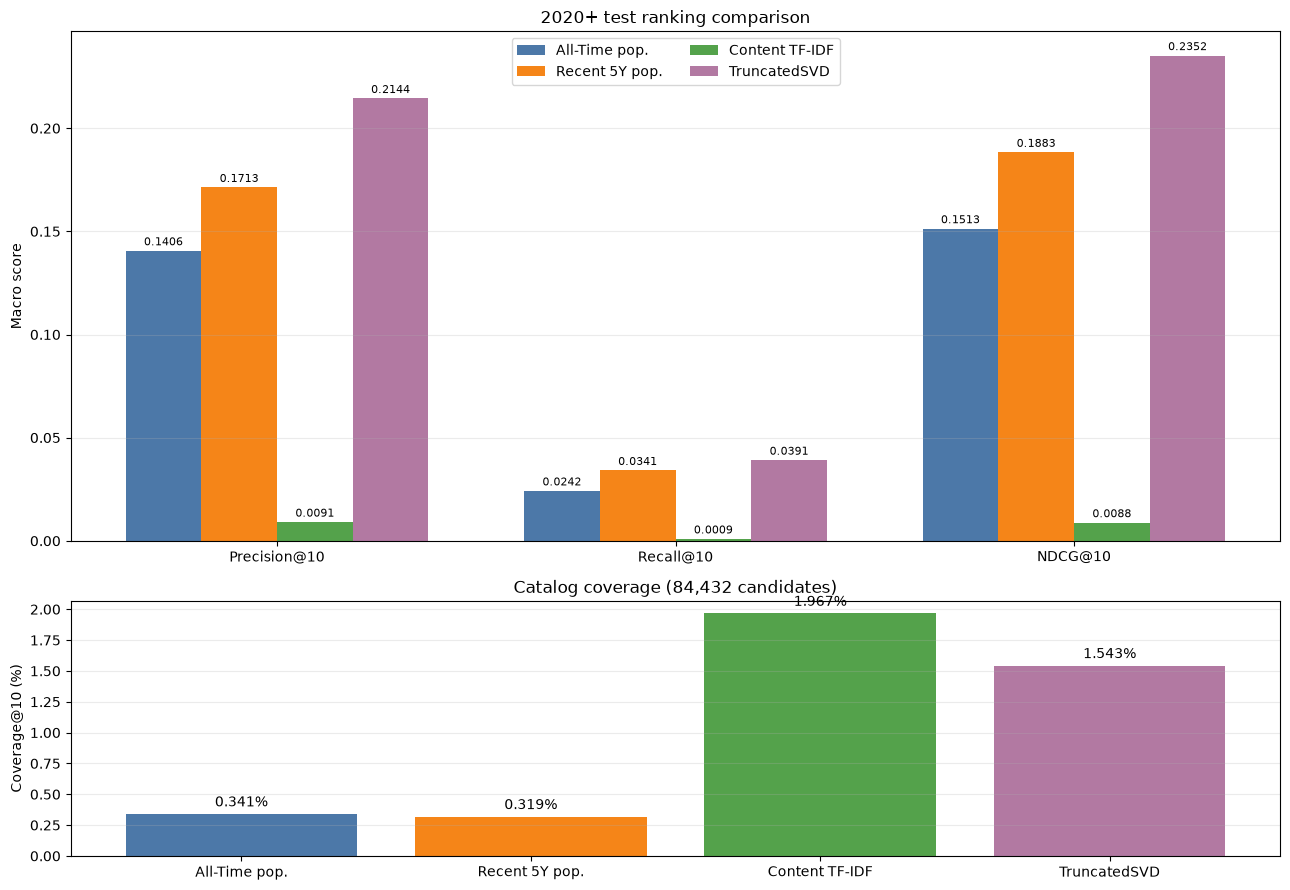

Saved: C:\OneriAlgoritmalariProjesi\results\figures\latent_svd_comparison.png


In [9]:
results_csv = os.path.join(results_path,'sonuclar.csv')
prior = pd.read_csv(results_csv, encoding='utf-8-sig')
compare_names = ['Adjusted Popularity (All-Time, 1995-2019)','Adjusted Popularity (Recent 5 Years, 2015-2019)','Content-Based TF-IDF + Cosine Similarity']
base = prior.loc[prior['Model'].isin(compare_names)].copy()
assert len(base) == 3, 'Expected official TASK 05 and TASK 06 rows.'
short_names = ['All-Time pop.','Recent 5Y pop.','Content TF-IDF','TruncatedSVD']
metric_keys = ['Precision@10','Recall@10','NDCG@10']
values = {key:[float(base.loc[base['Model']==name,key].iloc[0]) for name in compare_names]+[metrics[key]] for key in metric_keys}
cov_vals = [float(str(base.loc[base['Model']==name,'Coverage@10'].iloc[0]).replace('%','')) for name in compare_names]+[metrics['Coverage@10']*100]
colors=['#4c78a8','#f58518','#54a24b','#b279a2']
fig,axes=plt.subplots(2,1,figsize=(13,9),gridspec_kw={'height_ratios':[2,1]})
x=np.arange(len(metric_keys)); width=.19
for j,name in enumerate(short_names):
    bars=axes[0].bar(x+(j-1.5)*width,[values[key][j] for key in metric_keys],width,label=name,color=colors[j])
    axes[0].bar_label(bars,fmt='%.4f',padding=2,fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(metric_keys); axes[0].set_ylabel('Macro score')
axes[0].set_title('2020+ test ranking comparison'); axes[0].legend(ncol=2); axes[0].grid(axis='y',alpha=.25)
bars=axes[1].bar(short_names,cov_vals,color=colors)
axes[1].bar_label(bars,labels=[f'{v:.3f}%' for v in cov_vals],padding=3)
axes[1].set_ylabel('Coverage@10 (%)'); axes[1].set_title('Catalog coverage (84,432 candidates)'); axes[1].grid(axis='y',alpha=.25)
fig.tight_layout()
figure_path=os.path.join(figures_path,'latent_svd_comparison.png')
fig.savefig(figure_path,dpi=300,bbox_inches='tight')
plt.show()
print(f'Saved: {figure_path}')


## 8. Sonuçları CSV’ye ekleme

Yeni SVD satırı mevcut sonuçların sonuna eklenir. Önceki modeller korunur; aynı model satırı zaten varsa mükerrer eklemeyi önlemek için işlem durur.


In [10]:
existing_models=set(prior['Model'].astype(str))
assert metrics_row['Model'] not in existing_models, 'SVD row already exists in CSV; refusing duplicate append.'
with open(results_csv,'a',encoding='utf-8',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(prior.columns),extrasaction='raise')
    writer.writerow(metrics_row)
updated=pd.read_csv(results_csv,encoding='utf-8-sig')
assert len(updated)==len(prior)+1 and updated.iloc[-1]['Model']==metrics_row['Model']
print(f'Appended SVD row; existing rows preserved: {len(prior)} -> {len(updated)}')
display(updated.tail(5))


Appended SVD row; existing rows preserved: 4 -> 5


,Model,Precision@10,Recall@10,NDCG@10,Coverage@10,Benzersiz_Oneri_Sayisi,Model_Kapasitesi,Parametreler,Notlar
0,[Ön Aday / Test-Tuned] Adjusted Popularity Bas...,0.138800,0.024800,0.148000,0.327%,276,71.01% (59952/84432),"beta=50000, cutoff=2020-01-01, k_core=0",Eski test-tuned denemesi; sızıntılı beta seçim...
1,"Adjusted Popularity (All-Time, 1995-2019)",0.140600,0.024200,0.151300,0.341%,288,"71.01% (59,952/84,432)","beta=1000000, cutoff=2020-01-01, window=1995-2019",Resmi Benchmark; validation beta=1000000; goru...
2,"Adjusted Popularity (Recent 5 Years, 2015-2019)",0.171300,0.034100,0.188300,0.319%,269,"69.94% (59,050/84,432)","beta=300000, cutoff=2020-01-01, window=2015-2019",Resmi Benchmark; validation beta=300000; gorul...
3,Content-Based TF-IDF + Cosine Similarity,0.009070,0.000915,0.008778,1.967%,1661,"84,404/84,432 TF-IDF-vector items (99.97%)",title+genres; word 1-2 grams; min_df=1; fit on...,"U_eval=7,817; test>=2020-01-01; seen excluded;..."
4,Latent Factor Model (TruncatedSVD),0.214417,0.039084,0.235203,1.543%,1303,"59,952/84,432 candidates with latent item fact...",TruncatedSVD; n_components=40; n_iter=5; expli...,"U_eval=7,817; test>=2020-01-01; seen excluded;..."


## 9. Değerlendirme notu

Bu model yalnızca eğitimde etkileşim almış filmler için item faktörü üretir. Böylece 24.480 eğitim-soğuk aday puanlanamaz ve önerilemez; bunların test hedefleri Recall paydasında durduğu için modelin teorik erişim tavanı düşer. Coverage ise bütün 84.432 aday üzerinden hesaplanır. Faktör sayısı seçimi yalnızca 2019 validation NDCG@10 ile yapılmıştır; 2020+ test metriği seçimde kullanılmamıştır.
